# Choosing one training target per identity

`Facial` maps **N frames of a person onto a single image**, so training it needs one target
image per identity. This notebook picks that frame.

Two things decide which frame is a good target:

1. **How well a recogniser identifies it.** The target is the best the reconstruction can
   ever be, so a mediocre target caps the whole model.
2. **Pose, consistently across identities.** `FacialAggregator` pools with a *fixed* learned
   query, so nothing tells the decoder which pose to produce. If the targets point in all
   directions the decoder can only learn their average, which is a blurry face.

Those two are nearly independent (measured: Spearman 0.09), so we use both: shortlist the
frames the recogniser identifies best, then take the most frontal one of those.

The ArcFace embedding norm, which the earlier notebook used, turns out to measure neither
— selecting on it is no better than picking a frame at random.

In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

from meles.detection import ARCFACE_TEMPLATE, default_detector, umeyama
from meles.embedding_aggregation import normalized
from meles.frame_embedder import FrameEmbedder, models

DATA_PATH = Path("../../data")
SHORTLIST = 50  # frames per identity kept after the identifiability ranking

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm

In [2]:
structure = pd.read_parquet(DATA_PATH / "ytfaces.parquet")
structure

,identity,video,frame,frame_suffix,path
0,Aaron_Eckhart,0,aligned_detect_0.555.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.555.jpg
1,Aaron_Eckhart,0,aligned_detect_0.556.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.556.jpg
2,Aaron_Eckhart,0,aligned_detect_0.557.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.557.jpg
3,Aaron_Eckhart,0,aligned_detect_0.558.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.558.jpg
4,Aaron_Eckhart,0,aligned_detect_0.559.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.559.jpg
...,...,...,...,...,...
130722,Zulfiqar_Ahmed,4,aligned_detect_4.225.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.225.jpg
130723,Zulfiqar_Ahmed,4,aligned_detect_4.226.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.226.jpg
130724,Zulfiqar_Ahmed,4,aligned_detect_4.227.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.227.jpg
130725,Zulfiqar_Ahmed,4,aligned_detect_4.228.jpg,.jpg,ytfaces/Zulfiqar_Ahmed/4/aligned_detect_4.228.jpg


## 1. Embed every frame

One ArcFace embedding per frame. This is the slow step (~15 min for 130k frames), so the
result is cached next to the dataset.

In [3]:
EMBEDDINGS_PATH = DATA_PATH / "ytfaces_embeddings.parquet"

if EMBEDDINGS_PATH.exists():
    structure = pd.read_parquet(EMBEDDINGS_PATH)
else:
    arcface = FrameEmbedder(models.ARCFACE)
    structure["embedding"] = arcface.embed([str(DATA_PATH / path) for path in structure["path"]])
    structure.to_parquet(EMBEDDINGS_PATH, index=False)

# Unit vectors, so every comparison below is a plain cosine. Normalising matters: without it
# the long vectors dominate and we would be ranking by embedding norm again.
unit = np.asarray(normalized(np.stack(structure["embedding"].apply(np.asarray).values)), dtype=np.float32)
unit.shape

(130727, 512)

## 2. How well is each frame identified?

Score every frame the way the experiment's classifier would, as a **margin**:

    margin = similarity to its own identity  -  similarity to the closest other identity

The "own identity" half is computed against that identity's **other videos only**.
Neighbouring frames of one shot are near-duplicates, so comparing a frame against its own
video would measure redundancy rather than identifiability — the same trap the fold split
exists to avoid.

In [4]:
identities = np.array(sorted(structure["identity"].unique()))
identity_of = structure["identity"].values
video_of = structure["video"].values

# The gallery an attacker would hold: one mean embedding per identity.
gallery = np.stack([unit[identity_of == name].mean(axis=0) for name in identities])
gallery /= np.linalg.norm(gallery, axis=1, keepdims=True)

# Genuine similarity, leaving the frame's own video out of its identity's centroid.
genuine = np.zeros(len(structure), dtype=np.float32)
for name in tqdm(identities, desc="genuine similarity"):
    rows = identity_of == name
    for video in np.unique(video_of[rows]):
        centroid = unit[rows & (video_of != video)].mean(axis=0)
        held_out = rows & (video_of == video)
        genuine[held_out] = unit[held_out] @ (centroid / np.linalg.norm(centroid))

# Impostor similarity: the best match among all the other identities.
similarity = unit @ gallery.T
similarity[np.arange(len(structure)), np.searchsorted(identities, identity_of)] = -np.inf

structure["margin"] = genuine - similarity.max(axis=1)
structure["margin"].describe()

genuine similarity: 100%|██████████| 533/533 [00:06<00:00, 76.22it/s]

count    130727.000000
mean          0.363519
std           0.179612
min          -0.768293
25%           0.268100
50%           0.391139
75%           0.489554
max           0.771393
Name: margin, dtype: float64

## 3. How frontal is each frame?

`umeyama` fits a **similarity** transform — rotation, uniform scale, translation — from the
five detected landmarks onto `ARCFACE_TEMPLATE`, which is the canonical *frontal* layout. A
similarity transform cannot represent out-of-plane rotation, so whatever error is left after
the best fit *is* the yaw and pitch. Lower is more frontal.

This needs a detection pass, so we only run it on the shortlist rather than all 130k frames.

In [5]:
def frontality(landmarks):
    """RMS distance to the frontal template after the best similarity fit, in template pixels."""
    matrix = umeyama(landmarks, ARCFACE_TEMPLATE)
    aligned = landmarks @ matrix[:, :2].T + matrix[:, 2]
    return float(np.sqrt(((aligned - ARCFACE_TEMPLATE) ** 2).sum(axis=1).mean()))


# The frames the recogniser identifies best, per identity.
shortlist = structure.sort_values("margin", ascending=False).groupby("identity").head(SHORTLIST).copy()

residuals = []
for path in tqdm(shortlist["path"], desc="frontality"):
    area = default_detector.detect_best(cv2.imread(str(DATA_PATH / path)))
    # A frame without landmarks sorts last rather than being dropped.
    residuals.append(frontality(np.asarray(area.landmarks, dtype=np.float64))
                     if area is not None and area.landmarks is not None else np.inf)

shortlist["residual"] = residuals
shortlist["residual"].describe()

frontality: 100%|██████████| 26650/26650 [02:30<00:00, 177.24it/s]

count    26650.000000
mean         3.275442
std          1.200956
min          0.290179
25%          2.520273
50%          3.111476
75%          3.778743
max         14.874342
Name: residual, dtype: float64

## 4. Pick the target

The most frontal frame of each identity's shortlist.

In [6]:
targets = shortlist.loc[shortlist.groupby("identity")["residual"].idxmin()].reset_index(drop=True)

print(f"targets:            {len(targets):>8,}")
print(f"mean margin:        {targets['margin'].mean():>8.3f}   (all frames: {structure['margin'].mean():.3f})")
print(f"mean residual:      {targets['residual'].mean():>8.3f} px")
print(f"residual spread SD: {targets['residual'].std():>8.3f} px")

targets.drop(columns="embedding").head()

targets:                 533
mean margin:           0.456   (all frames: 0.364)
mean residual:         1.904 px
residual spread SD:    0.778 px

,identity,video,frame,frame_suffix,path,margin,residual
0,Aaron_Eckhart,0,aligned_detect_0.586.jpg,.jpg,ytfaces/Aaron_Eckhart/0/aligned_detect_0.586.jpg,0.409920,2.107932
1,Abdel_Aziz_Al-Hakim,0,aligned_detect_0.1022.jpg,.jpg,ytfaces/Abdel_Aziz_Al-Hakim/0/aligned_detect_0...,0.055595,2.301788
2,Abdullah_Gul,3,aligned_detect_3.384.jpg,.jpg,ytfaces/Abdullah_Gul/3/aligned_detect_3.384.jpg,0.503139,1.308786
3,Abel_Pacheco,3,aligned_detect_3.2732.jpg,.jpg,ytfaces/Abel_Pacheco/3/aligned_detect_3.2732.jpg,0.195333,1.354910
4,Adam_Sandler,0,aligned_detect_0.235.jpg,.jpg,ytfaces/Adam_Sandler/0/aligned_detect_0.235.jpg,0.227899,0.914877


Both numbers should have moved the right way: a higher margin than the dataset average means
the targets are easier to identify, and a small residual spread means they share a pose.

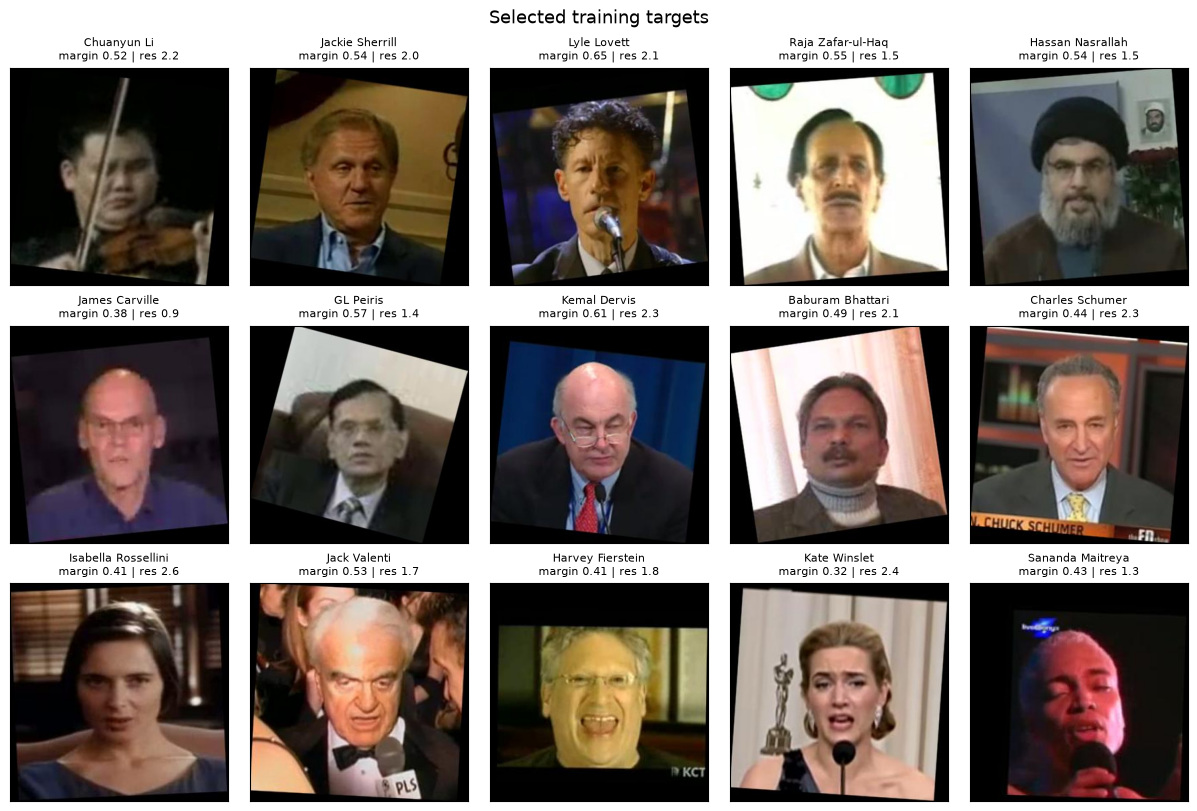

In [7]:
N_SHOWN = 15

sample = targets.sample(n=N_SHOWN, random_state=1)

fig, axes = plt.subplots(3, 5, figsize=(12, 8), layout="constrained")
for ax, (_, target) in zip(axes.flat, sample.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA_PATH / target["path"])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{target['identity'].replace('_', ' ')}\nmargin {target['margin']:.2f} | res {target['residual']:.1f}",
                 fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Selected training targets", fontsize=13)
plt.show()

## 5. Save

One row per identity, pointing at the frame to use as that identity's target.

In [8]:
targets.drop(columns="embedding").to_parquet(DATA_PATH / "ytfaces_targets.parquet", index=False)